### This notebook calculates GMM parameters (weights, means, variances) using 5-fold cross-validation via `maple_fep`'s `fit_gmm_cv`.
#### uncomment edge lines to get edge parameters

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
from tqdm import tqdm

from maple_fep.utils import fit_gmm_cv

In [ ]:
file_path = "openfe_dataset_nodes.csv" # nodes
# file_path = "openfe_dataset_edges.csv" # edges
data = pd.read_csv(file_path)
data

,Source,Destination,Experimental DeltaDeltaG,DeltaDeltaG,DeltaDeltaG error,Dataset
0,76d999c7-4d5f-4653-814e-e868c5c23785,3969880d-6a34-4516-b4c3-a346f9373695,0.381995,-1.146342,0.123087,MERS
1,dde3702a-1427-46c1-bb14-8c34aa13c2aa,76d999c7-4d5f-4653-814e-e868c5c23785,-0.491141,0.513294,0.146139,MERS
2,b4cb63e2-9ae3-4fda-afb8-e0d173351a56,1128a101-957b-4cc3-a401-f71fa237b4e3,0.968623,1.305476,0.049725,MERS
3,79312212-d1ec-48d1-9824-fb26415ccdb8,76d999c7-4d5f-4653-814e-e868c5c23785,-0.422923,2.592839,0.136562,MERS
4,2fc6f0f1-70ea-4cd0-889a-de41887f8670,3969880d-6a34-4516-b4c3-a346f9373695,-0.327420,-0.415763,0.097200,MERS
...,...,...,...,...,...,...
1070,ligand11,ligand12,2.561862,2.972964,0.581552,target_D
1071,ligand0,ligand11,0.302856,-1.066851,0.362096,target_D
1072,ligand8,ligand3,0.848769,2.378522,0.364104,target_D
1073,ligand2,ligand3,1.876150,4.666790,0.309203,target_D


In [ ]:
## nodes
data_1d = data['Exp. DeltaG'].values.flatten()
seed = 0


## edges
# data_1d = data['Experimental DeltaDeltaG'].values.flatten()
# seed = 42

print('mean of data: ', np.mean(data_1d))
print('variance of data: ', np.var(data_1d, axis=0))
data_1d.shape

mean of data:  0.3087141213445953
variance of data:  2.524832483485087


(1075,)

### Need to zero-center node values 
skip below for edge values

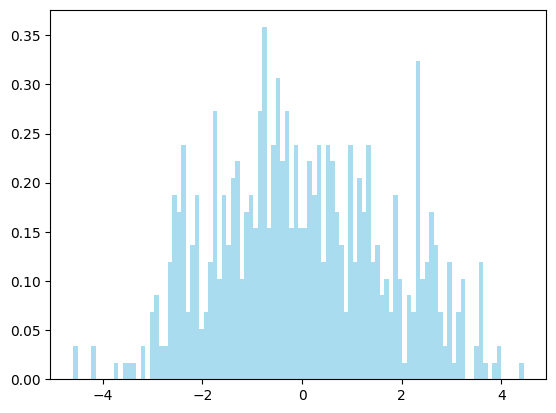

In [4]:
data_1d = data_1d - np.mean(data_1d)
plt.hist(data_1d, bins=100, density=True, alpha=0.7, color='skyblue')
plt.show()

In [ ]:
# Cross-validated component selection + refit, delegated to maple_fep.
# fit_gmm_cv picks K by 5-fold CV log-likelihood over k=1..10, then refits
# the chosen K on all data. Returns (GMMParams, GMMSelectionResult); the
# GMMParams plug straight into MixtureVIConfig(prior_gmm=...) / likelihood_gmm.
params, selection = fit_gmm_cv(
    data_1d,
    k_values=list(range(1, 11)),   # search over 1..10 components
    n_splits=5,                    # 5-fold cross-validation
    random_state=seed,
)

for k, score in zip(selection.k_values, selection.cv_scores):
    print(f"k={k:2d}, mean CV log-likelihood={score:.4f}")

print(f"\nBest k: {selection.best_k} (mean CV log-likelihood={selection.best_score:.4f})")
print(f"means: {np.array(params.means)}")
print(f"variances: {np.array(params.variances)}")
print(f"weights: {np.array(params.weights)}")